=== PASO 1: CARGA Y LIMPIEZA DE DATOS ===

=== EVALUANDO 4 MODELOS EN EL CONJUNTO DE PRUEBA ===
Entrenando DecisionTreeClassifier...
  -> DecisionTreeClassifier finalizado con éxito.
Entrenando RandomForestClassifier...
  -> RandomForestClassifier finalizado con éxito.
Entrenando KNeighborsClassifier...


  File "c:\Users\david\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\david\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\david\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\david\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


  -> KNeighborsClassifier finalizado con éxito.
Entrenando LGBMClassifier...
  ⚠️ Error evaluando LGBMClassifier: exception: access violation reading 0x0000000000000000

TABLA COMPARATIVA DE MODELOS (ORDENADOS POR AUC-PR)
                Modelo  Accuracy  Precision  Recall  F1-Score  AUC-ROC  AUC-PR
RandomForestClassifier    0.9973     0.9677  0.9819    0.9747   0.9956  0.9841
  KNeighborsClassifier    0.9937     0.9699  0.9083    0.9381   0.9788  0.9469
DecisionTreeClassifier    0.9938     0.9288  0.9566    0.9425   0.9764  0.8929

🏆 MEJOR MODELO SELECCIONADO: RandomForestClassifier
   Métricas -> AUC-PR: 0.9841 | AUC-ROC: 0.9956 | Recall: 0.9819


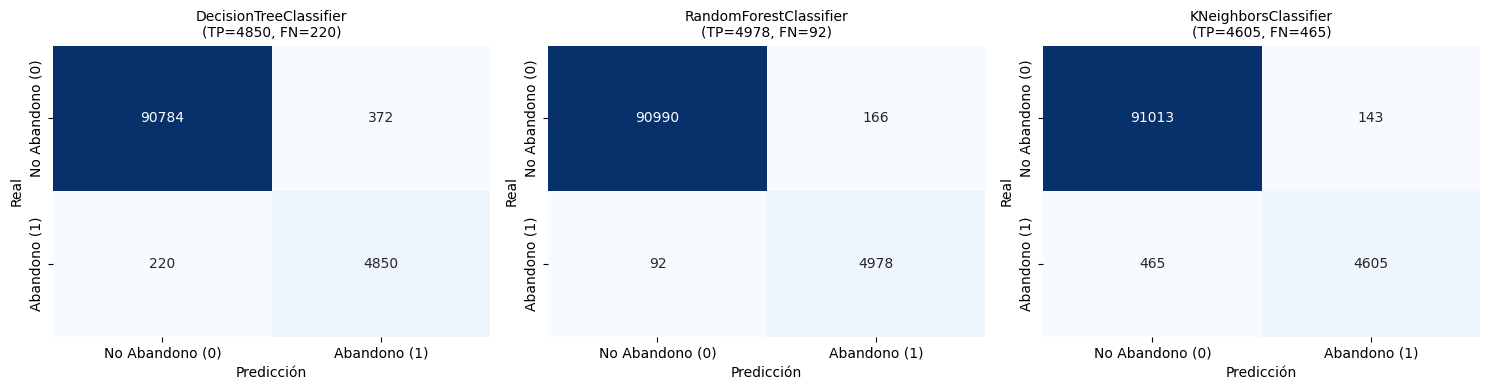


[OK] El mejor modelo 'RandomForestClassifier' y sus artefactos han sido guardados en 'modelo_abandono.pkl'


In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

# Cargar LightGBM
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

def cargar_y_preparar_datos(filepath="trainning_secu.csv"):
    df = pd.read_csv(filepath)
    
    # 1. Eliminar identificadores y datos categóricos no procesados directamente
    columnas_excluir = ['curp', 'cct', 'ciclo', 'tipo_movimiento', 'abandono']
    columnas_excluir_existentes = [col for col in columnas_excluir if col in df.columns]
    
    X = df.drop(columns=columnas_excluir_existentes)
    y = df['abandono']
    
    # 2. Convertir todas las columnas a numérico estricto
    for col in X.columns:
        X[col] = pd.to_numeric(X[col], errors='coerce')
        
    numeric_cols = X.select_dtypes(include=['int64', 'float64', 'float32', 'int32']).columns.tolist()
    X = X[numeric_cols]
    
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y), numeric_cols

def construir_modelos():
    modelos = {
        'DecisionTreeClassifier': Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('clf', DecisionTreeClassifier(random_state=42, class_weight='balanced'))
        ]),
        'RandomForestClassifier': Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, class_weight='balanced', n_jobs=-1))
        ]),
        'KNeighborsClassifier': Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=7, n_jobs=-1))
        ])
    }
    
    if HAS_LGBM:
        # Configuración segura de LightGBM para evitar Access Violation en Windows
        modelos['LGBMClassifier'] = Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('clf', LGBMClassifier(
                random_state=42,
                class_weight='balanced',
                n_estimators=100,
                n_jobs=1,
                verbose=-1,
                force_col_wise=True
            ))
        ])
        
    return modelos

def evaluar_experimento():
    print("=== PASO 1: CARGA Y LIMPIEZA DE DATOS ===")
    (X_train, X_test, y_train, y_test), feature_names = cargar_y_preparar_datos()
    
    # Convertir a float32 para garantizar alineación de memoria continua en C++
    X_train = np.ascontiguousarray(X_train.astype(np.float32))
    X_test = np.ascontiguousarray(X_test.astype(np.float32))
    y_train = np.ascontiguousarray(y_train.values if hasattr(y_train, 'values') else y_train)
    y_test = np.ascontiguousarray(y_test.values if hasattr(y_test, 'values') else y_test)
    
    modelos = construir_modelos()
    resultados = []
    matrices_confusion = {}
    modelos_entrenados = {}

    print(f"\n=== EVALUANDO {len(modelos)} MODELOS EN EL CONJUNTO DE PRUEBA ===")
    
    for nombre, pipeline in modelos.items():
        print(f"Entrenando {nombre}...")
        try:
            pipeline.fit(X_train, y_train)
            
            y_pred = pipeline.predict(X_test)
            y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else y_pred

            acc = accuracy_score(y_test, y_pred)
            prec = precision_score(y_test, y_pred, zero_division=0)
            rec = recall_score(y_test, y_pred, zero_division=0)
            f1 = f1_score(y_test, y_pred, zero_division=0)
            roc_auc = roc_auc_score(y_test, y_proba)
            pr_auc = average_precision_score(y_test, y_proba)
            cm = confusion_matrix(y_test, y_pred)

            resultados.append({
                'Modelo': nombre,
                'Accuracy': round(acc, 4),
                'Precision': round(prec, 4),
                'Recall': round(rec, 4),
                'F1-Score': round(f1, 4),
                'AUC-ROC': round(roc_auc, 4),
                'AUC-PR': round(pr_auc, 4)
            })
            
            matrices_confusion[nombre] = cm
            modelos_entrenados[nombre] = pipeline
            print(f"  -> {nombre} finalizado con éxito.")
            
        except Exception as e:
            print(f"  ⚠️ Error evaluando {nombre}: {e}")

    if not resultados:
        print("No se pudo evaluar ningún modelo.")
        return

    # Tabla resumen ordenada por AUC-PR
    df_resultados = pd.DataFrame(resultados).sort_values(by='AUC-PR', ascending=False).reset_index(drop=True)
    
    print("\n" + "="*80)
    print("TABLA COMPARATIVA DE MODELOS (ORDENADOS POR AUC-PR)")
    print("="*80)
    print(df_resultados.to_string(index=False))
    
    mejor_modelo_nombre = df_resultados.loc[0, 'Modelo']
    mejor_pipeline = modelos_entrenados[mejor_modelo_nombre]
    
    print("\n" + "="*80)
    print(f"🏆 MEJOR MODELO SELECCIONADO: {mejor_modelo_nombre}")
    print(f"   Métricas -> AUC-PR: {df_resultados.loc[0, 'AUC-PR']} | AUC-ROC: {df_resultados.loc[0, 'AUC-ROC']} | Recall: {df_resultados.loc[0, 'Recall']}")
    print("="*80)

    # Graficar Matrices de Confusión
    fig, axes = plt.subplots(1, len(matrices_confusion), figsize=(5 * len(matrices_confusion), 4))
    if len(matrices_confusion) == 1:
        axes = [axes]

    for ax, (nombre, cm) in zip(axes, matrices_confusion.items()):
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                    xticklabels=['No Abandono (0)', 'Abandono (1)'],
                    yticklabels=['No Abandono (0)', 'Abandono (1)'])
        ax.set_title(f'{nombre}\n(TP={cm[1,1]}, FN={cm[1,0]})', fontsize=10)
        ax.set_xlabel('Predicción')
        ax.set_ylabel('Real')

    plt.tight_layout()
    plt.savefig('matrices_confusion_comparativa.png', dpi=300)
    plt.show()

    # Guardar Artefacto Final
    artefacto_final = {
        'pipeline': mejor_pipeline,
        'features': feature_names,
        'nombre_modelo': mejor_modelo_nombre,
        'metricas_comparativas': df_resultados
    }
    
    output_path = "modelo_abandono.pkl"
    joblib.dump(artefacto_final, output_path)
    print(f"\n[OK] El mejor modelo '{mejor_modelo_nombre}' y sus artefactos han sido guardados en '{output_path}'")

if __name__ == "__main__":
    evaluar_experimento()